In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

outpath = './pdf_plots/'


Ab42: NCPR = -0.071  (net charge = -3, N = 42)
aSyn: NCPR = -0.064  (net charge = -9, N = 140)
Tau: NCPR = 0.005  (net charge = 2, N = 441)


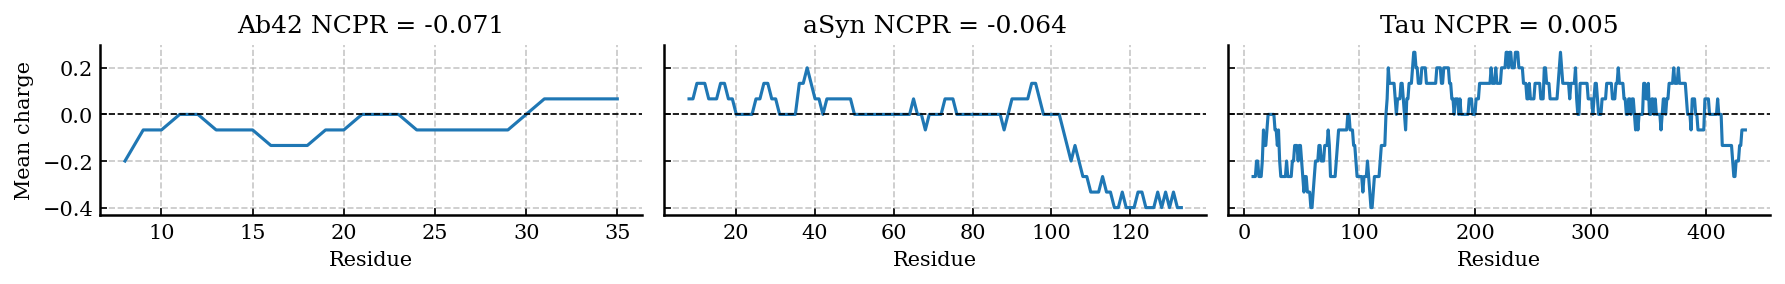

In [14]:
# sequence properties

seq_dict = {}
for prot in ['Ab42', 'aSyn', 'Tau']:
    with open(f'../EXP_DATA/{prot}.fasta', 'r') as f:
        lines = f.readlines()
    seq = lines[-1].strip()
    seq_dict[prot] = seq

# calculate NCPR and sliding-window mean charge (window = 9 residues)

charge_dict = {
    'K':  1.0,
    'R':  1.0,
    'D': -1.0,
    'E': -1.0,
}

window = 15

fig, axes = plt.subplots(1, 3, figsize=(12, 2.), sharey=True)

for ax, prot in zip(axes, ['Ab42', 'aSyn', 'Tau']):

    seq = seq_dict[prot]
    charges = np.array([charge_dict.get(aa, 0.0) for aa in seq])

    # net charge per residue
    ncpr = charges.sum() / len(seq)
    print(f'{prot}: NCPR = {ncpr:.3f}  (net charge = {charges.sum():.0f}, N = {len(seq)})')

    # centred sliding-window average charge
    mean_charge = np.convolve(charges, np.ones(window) / window, mode='valid')
    residues = np.arange(window // 2 + 1, len(seq) - window // 2 + 1)

    ax.plot(residues, mean_charge, lw=1.5)
    ax.axhline(0, color='k', ls='--', lw=0.8)

    ax.set_title(f'{prot} NCPR = {ncpr:.3f}')
    ax.set_xlabel('Residue')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.xaxis.set_ticks_position('bottom')

axes[0].set_ylabel('Mean charge')

plt.tight_layout()
plt.savefig(outpath+'seq_charge_properties.pdf')
plt.show()


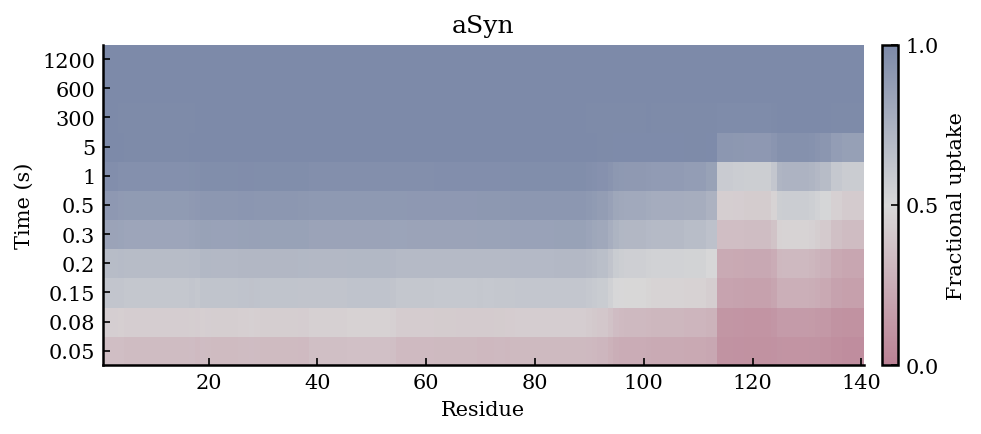

In [65]:


protein = 'aSyn'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')

# colour scale: 0 -> 0.5 -> 1
cmap = LinearSegmentedColormap.from_list('uptake_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its uptake to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------
times = np.sort(data['Time (s)'].dropna().unique())
residues = np.arange(int(data['Start'].min()), int(data['End'].max()) + 1)

uptake = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = data[data['Time (s)'] == t]
    for j, res in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= res) & (df_t['End'] >= res), 'Rel. Uptake'].values
        if len(vals) > 0:
            uptake[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# Geometric midpoints are used for time because the y-axis is log.
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)

log_times = np.log10(times)
log_edges = np.empty(len(times) + 1)
log_edges[1:-1] = (log_times[:-1] + log_times[1:]) / 2
log_edges[0] = log_times[0] - (log_edges[1] - log_times[0])
log_edges[-1] = log_times[-1] + (log_times[-1] - log_edges[-2])
y_edges = 10**log_edges

# ------------------------------------------------------------------
# Plot: equally sized rows for each labelling time
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, uptake, cmap=cmap, vmin=0, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein)

# label each equally sized row with the actual experimental time
ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Fractional uptake')
cbar.set_ticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig(outpath+f'{protein}_heatmap.pdf', dpi=300)
plt.show()

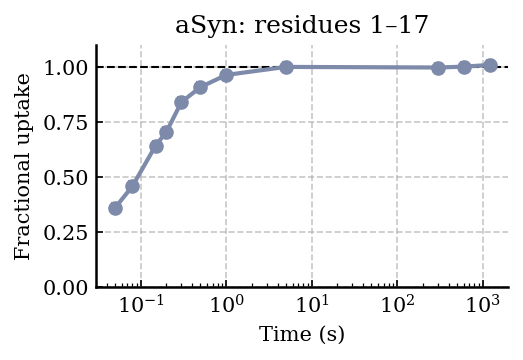

In [55]:
protein = 'aSyn'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 1
peptide_end = 17

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

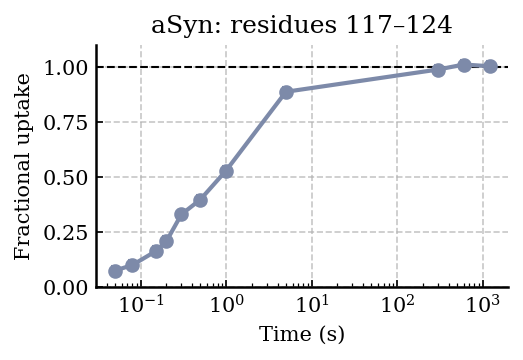

In [56]:
protein = 'aSyn'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 117
peptide_end = 124

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

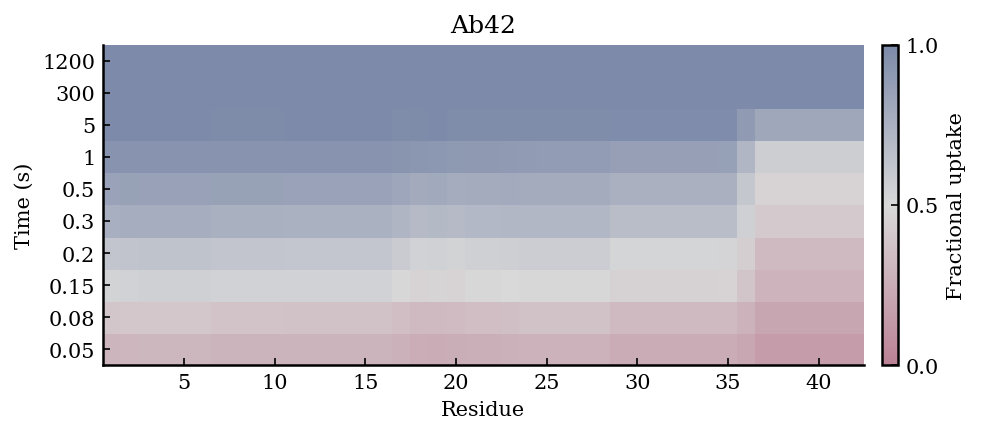

In [68]:


protein = 'Ab42'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')

# colour scale: 0 -> 0.5 -> 1
cmap = LinearSegmentedColormap.from_list('uptake_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its uptake to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------
times = np.sort(data['Time (s)'].dropna().unique())
residues = np.arange(int(data['Start'].min()), int(data['End'].max()) + 1)

uptake = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = data[data['Time (s)'] == t]
    for j, res in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= res) & (df_t['End'] >= res), 'Rel. Uptake'].values
        if len(vals) > 0:
            uptake[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# Geometric midpoints are used for time because the y-axis is log.
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)

log_times = np.log10(times)
log_edges = np.empty(len(times) + 1)
log_edges[1:-1] = (log_times[:-1] + log_times[1:]) / 2
log_edges[0] = log_times[0] - (log_edges[1] - log_times[0])
log_edges[-1] = log_times[-1] + (log_times[-1] - log_edges[-2])
y_edges = 10**log_edges

# ------------------------------------------------------------------
# Plot: equally sized rows for each labelling time
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, uptake, cmap=cmap, vmin=0, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein)

# label each equally sized row with the actual experimental time
ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Fractional uptake')
cbar.set_ticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig(outpath+f'{protein}_heatmap.pdf', dpi=300)
plt.show()

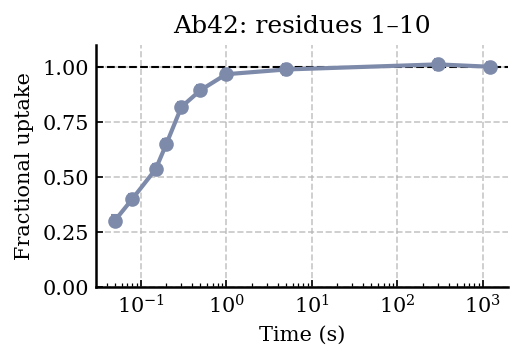

In [58]:
protein = 'Ab42'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 1
peptide_end = 10

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

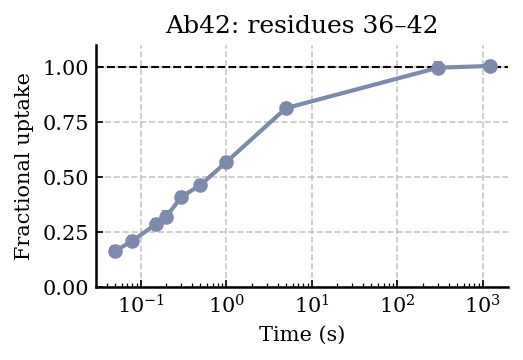

In [59]:
protein = 'Ab42'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 36
peptide_end = 42

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

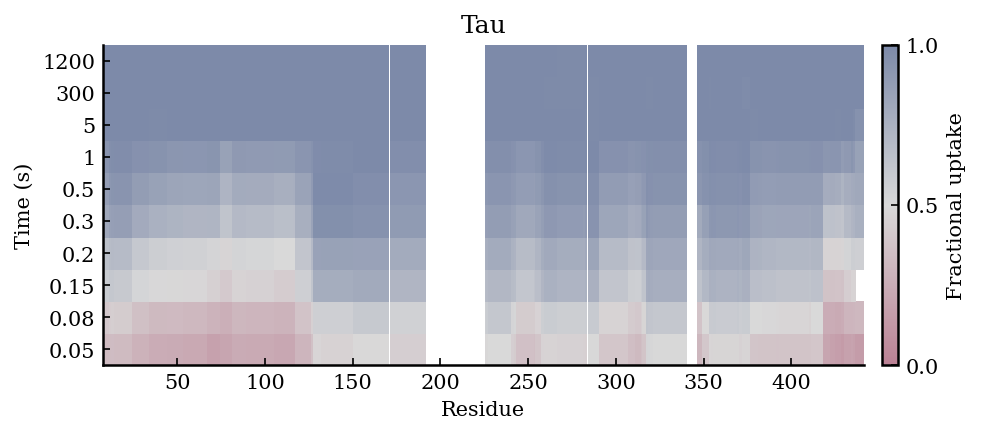

In [69]:


protein = 'Tau'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')

# colour scale: 0 -> 0.5 -> 1
cmap = LinearSegmentedColormap.from_list('uptake_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its uptake to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------
times = np.sort(data['Time (s)'].dropna().unique())
residues = np.arange(int(data['Start'].min()), int(data['End'].max()) + 1)

uptake = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = data[data['Time (s)'] == t]
    for j, res in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= res) & (df_t['End'] >= res), 'Rel. Uptake'].values
        if len(vals) > 0:
            uptake[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# Geometric midpoints are used for time because the y-axis is log.
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)

log_times = np.log10(times)
log_edges = np.empty(len(times) + 1)
log_edges[1:-1] = (log_times[:-1] + log_times[1:]) / 2
log_edges[0] = log_times[0] - (log_edges[1] - log_times[0])
log_edges[-1] = log_times[-1] + (log_times[-1] - log_edges[-2])
y_edges = 10**log_edges

# ------------------------------------------------------------------
# Plot: equally sized rows for each labelling time
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, uptake, cmap=cmap, vmin=0, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein)

# label each equally sized row with the actual experimental time
ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Fractional uptake')
cbar.set_ticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig(outpath+f'{protein}_heatmap.pdf', dpi=300)
plt.show()

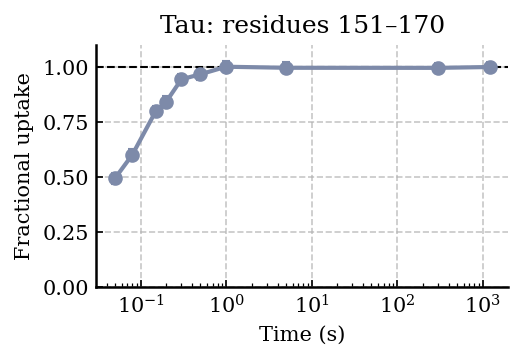

In [61]:
protein = 'Tau'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 151
peptide_end = 170

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

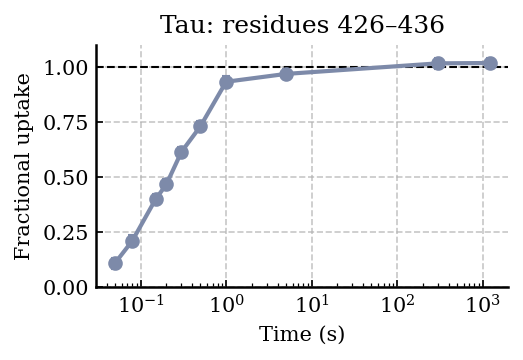

In [62]:
protein = 'Tau'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 426
peptide_end = 436

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

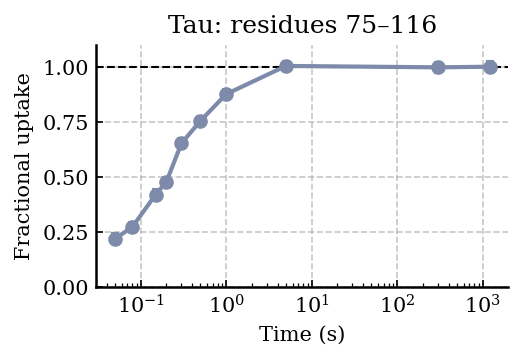

In [63]:
protein = 'Tau'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')
peptide_start = 75
peptide_end = 116

pep = data[(data['Start'] == peptide_start) & (data['End'] == peptide_end)].copy()
pep = pep.sort_values('Time (s)')

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.errorbar(pep['Time (s)'], pep['Rel. Uptake'], yerr=pep['Rel. Uptake SD'], fmt='o-', capsize=2, color="#7D8AA9")
ax.axhline(1.0, color='black', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Fractional uptake')
ax.set_ylim(0, 1.1)
ax.set_title(f'{protein}: residues {peptide_start}–{peptide_end}')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+f'{protein}_{peptide_start}_{peptide_end}_uptake.pdf')
plt.show()

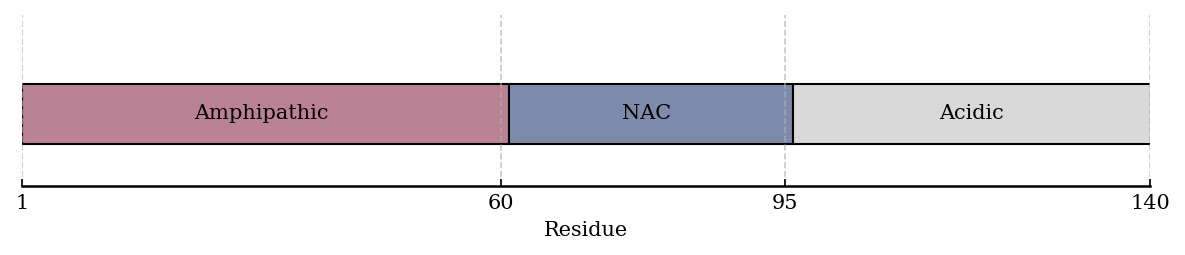

In [73]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

savefile = 'alpha_synuclein_domain_diagram.pdf'

domains = [('Amphipathic', 1, 60, '#BB8194'),
           ('NAC', 61, 95, '#7D8AA9'),
           ('Acidic', 96, 140, '#D9D9D9')]

fig, ax = plt.subplots(figsize=(8, 1.8))

y, h = 0.4, 0.28
for label, start, end, color in domains:
    ax.add_patch(Rectangle((start, y), end - start + 1, h, facecolor=color, edgecolor='black', linewidth=1))
    ax.text((start + end) / 2, y + h / 2, label, ha='center', va='center', fontsize=10)

ax.set_xlim(1, 140)
ax.set_ylim(0.2, 1.0)
ax.set_yticks([])
ax.set_xticks([1, 60, 95, 140])
ax.set_xlabel('Residue')
ax.tick_params(axis='x', top=False)
ax.tick_params(axis='y', left=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+savefile, bbox_inches='tight')
plt.show()

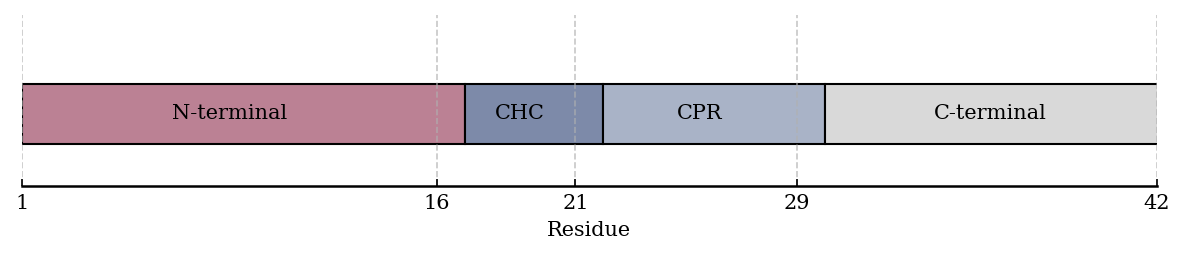

In [75]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

savefile = 'Ab42_domain_diagram.pdf'

domains = [('N-terminal', 1, 16, '#BB8194'), # metal binding region
           ('CHC', 17, 21, '#7D8AA9'), # central hydrophobic core
           ('CPR', 22, 29, '#A9B3C7'), # central polar region
           ('C-terminal', 30, 42, '#D9D9D9')] # cterminal hydrophobic region

fig, ax = plt.subplots(figsize=(8, 1.8))

y, h = 0.4, 0.28
for label, start, end, color in domains:
    ax.add_patch(Rectangle((start, y), end - start + 1, h, facecolor=color, edgecolor='black', linewidth=1))
    ax.text((start + end) / 2, y + h / 2, label, ha='center', va='center', fontsize=10)

ax.set_xlim(1, 42)
ax.set_ylim(0.2, 1.0)
ax.set_yticks([])
ax.set_xticks([1, 16, 21, 29, 42])
ax.set_xlabel('Residue')
ax.tick_params(axis='x', top=False)
ax.tick_params(axis='y', left=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+savefile, bbox_inches='tight')
plt.show()

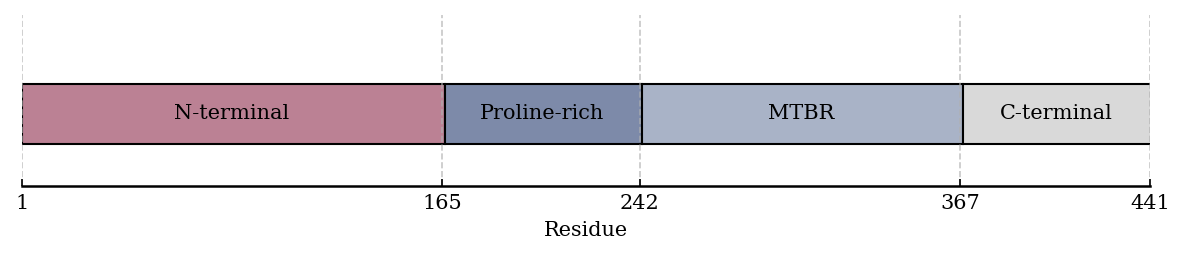

In [76]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

savefile = 'Tau_domain_diagram.pdf'

domains = [('N-terminal', 1, 165, '#BB8194'),
           ('Proline-rich', 166, 242, '#7D8AA9'),
           ('MTBR', 243, 367, '#A9B3C7'),
           ('C-terminal', 368, 441, '#D9D9D9')]

fig, ax = plt.subplots(figsize=(8, 1.8))

y, h = 0.4, 0.28
for label, start, end, color in domains:
    ax.add_patch(Rectangle((start, y), end - start + 1, h, facecolor=color, edgecolor='black', linewidth=1))
    ax.text((start + end) / 2, y + h / 2, label, ha='center', va='center', fontsize=10)

ax.set_xlim(1, 441)
ax.set_ylim(0.2, 1.0)
ax.set_yticks([])
ax.set_xticks([1, 165, 242, 367, 441])
ax.set_xlabel('Residue')
ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig(outpath+savefile, bbox_inches='tight')
plt.show()

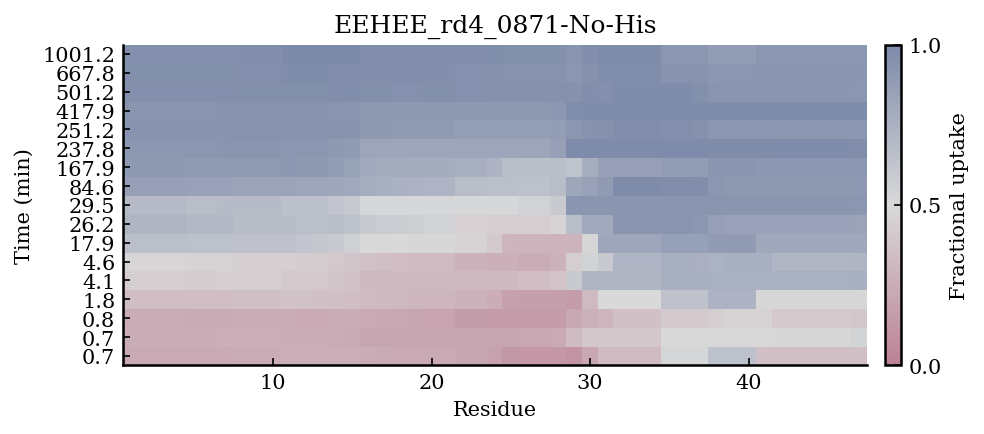

In [82]:
protein = 'EEHEE_rd4_0871-No-His'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')

# colour scale: 0 -> 0.5 -> 1
cmap = LinearSegmentedColormap.from_list('uptake_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its uptake to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(data['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(data['Start'].min()), int(data['End'].max()) + 1)

uptake = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = data[data['Time (s)'] == t]
    for j, res in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= res) & (df_t['End'] >= res), 'Rel. Uptake'].values
        if len(vals) > 0:
            uptake[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot: equally sized rows for each labelling time
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, uptake, cmap=cmap, vmin=0, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (min)')
ax.set_title(protein)

# label each equally sized row with the experimental time in minutes
ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:.1f}' for t in times_min])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Fractional uptake')
cbar.set_ticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig(outpath + f'{protein}_heatmap.pdf', dpi=300)
plt.show()

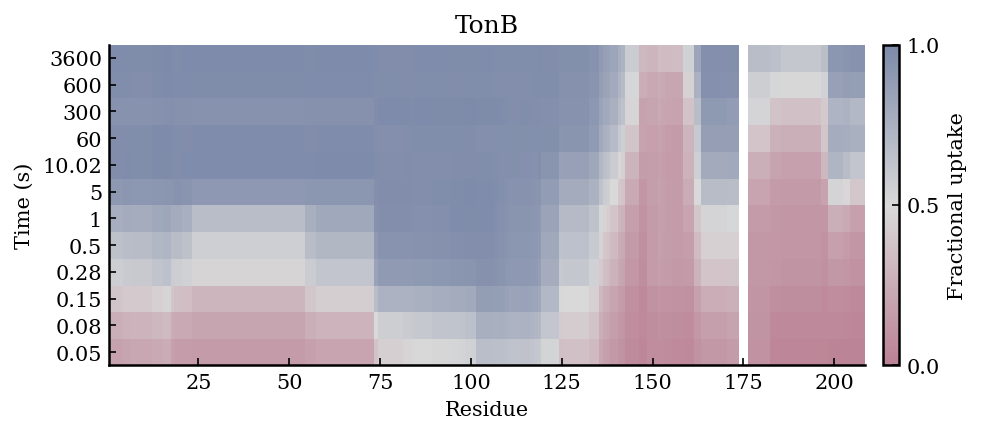

In [2]:


protein = 'TonB'
data = pd.read_csv(f'../EXP_DATA/{protein}.csv')

# colour scale: 0 -> 0.5 -> 1
cmap = LinearSegmentedColormap.from_list('uptake_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its uptake to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------
times = np.sort(data['Time (s)'].dropna().unique())
residues = np.arange(int(data['Start'].min()), int(data['End'].max()) + 1)

uptake = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = data[data['Time (s)'] == t]
    for j, res in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= res) & (df_t['End'] >= res), 'Rel. Uptake'].values
        if len(vals) > 0:
            uptake[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# Geometric midpoints are used for time because the y-axis is log.
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)

log_times = np.log10(times)
log_edges = np.empty(len(times) + 1)
log_edges[1:-1] = (log_times[:-1] + log_times[1:]) / 2
log_edges[0] = log_times[0] - (log_edges[1] - log_times[0])
log_edges[-1] = log_times[-1] + (log_times[-1] - log_edges[-2])
y_edges = 10**log_edges

# ------------------------------------------------------------------
# Plot: equally sized rows for each labelling time
# ------------------------------------------------------------------
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, uptake, cmap=cmap, vmin=0, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (s)')
ax.set_title(protein)

# label each equally sized row with the actual experimental time
ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:g}' for t in times])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Fractional uptake')
cbar.set_ticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig(outpath+f'{protein}_heatmap.pdf', dpi=300)
plt.show()